# Team A Phase III Model Development and Customer History

This notebook extends the original Random Forest experiment with Juan Franceschi's
Gradient Boosting and eight history-feature concepts. The corrected implementation
uses strictly earlier timestamp groups and separate historical context/review inputs.
It trains missing new models, reuses compatible saved artifacts, and documents
validation results. **It does not rerun the official test evaluation.**

Phase II's preparation notebook/report remain separate. The original Random Forest's
previously recorded test result belongs only to that baseline. New model comparisons
are validation-only, not independent test results. Synthetic transaction patterns do
not establish real banking performance.

In [1]:
from pathlib import Path
import base64, io, json, os, sys, zipfile, subprocess, importlib.util
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '4')
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
PROJECT = Path.cwd()
if not (PROJECT / 'history.py').exists():
    PROJECT = Path('/content/FraudShield_Phase_III') if IN_COLAB else Path.cwd() / '.notebook_code'
    PROJECT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(base64.b64decode('...'))) as archive:
        archive.extractall(PROJECT)
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(PROJECT / 'requirements-tested.txt')])
sys.path.insert(0, str(PROJECT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from train import train
from core import load_bundle, score_transactions, validate_input
from history import HISTORY_VERSION
from verify_context import verify
from shared.project_data import sha256
ARTIFACTS = PROJECT / 'artifacts'
print('History definition:', HISTORY_VERSION)


History definition: strict-timestamp-groups-v2


## 1 Obtain the full original dataset

Source: https://www.kaggle.com/datasets/kartik2112/fraud-detection
Generator: https://github.com/namebrandon/Sparkov_Data_Generation

Use both original CSVs, not the reduced Part II files. Set `DATA_DIR` below to
an existing folder, including a mounted Google Drive folder. In fresh Colab,
Run All opens a picker for both CSVs or the Kaggle ZIP if files are not found.
No Kaggle token is needed. Original files are read, not modified. The training
routine inspects official test inputs and chronology but never evaluates labels.

In [2]:
DATA_DIR = None  # Set Path('/content/drive/MyDrive/your_folder') if using mounted Drive.
if DATA_DIR is None:
    candidates = [PROJECT.parent / 'data', Path('/content/data')]
    if len(PROJECT.parents) >= 2:
        candidates.append(PROJECT.parents[1] / '01_Assignments/fraud')
    DATA_DIR = next((p for p in candidates if (p / 'fraudTrain.csv').exists() and (p / 'fraudTest.csv').exists()), None)
if DATA_DIR is None and IN_COLAB:
    from google.colab import files
    import shutil
    DATA_DIR = Path('/content/data')
    DATA_DIR.mkdir(exist_ok=True)
    uploaded = files.upload()
    for filename in uploaded:
        path = Path(filename)
        if path.name in ['fraudTrain.csv', 'fraudTest.csv']:
            shutil.copy2(path, DATA_DIR / path.name)
        elif path.suffix.lower() == '.zip':
            with zipfile.ZipFile(path) as archive:
                for member in archive.infolist():
                    name = Path(member.filename).name
                    if name in ['fraudTrain.csv', 'fraudTest.csv']:
                        with archive.open(member) as source, (DATA_DIR / name).open('wb') as target:
                            shutil.copyfileobj(source, target)
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR to the folder containing both original CSVs.')
DATA_DIR = Path(DATA_DIR)
assert all((DATA_DIR / name).exists() for name in ['fraudTrain.csv', 'fraudTest.csv'])
print('Original CSV directory:', DATA_DIR)


Original CSV directory: G:\1MDC_Education\CAI2820C_Artificial_Intelligence_App\01_Assignments\fraud


## 2 Train once and save separately

Use the earlier 1,037,340 development transactions for fitting and the later
259,335 for validation. Select thresholds by validation F1 subject to recall
at least 80% and precision at least 10% when feasible. No refitting on validation.
The original Random Forest evidence is retained, not retrained in this notebook.

The history model uses the earlier training transactions as context for validation.
All rows at the same timestamp are scored from strictly earlier times. Previous
merchant distance uses the centroid when several merchants share the previous
timestamp. Cold starts have explicit default history values. No fraud label or
numeric card ID is an input. Use a NEW output directory for changed experiments;
do not reuse old history models after changing feature definitions.

In [3]:
experiments = {}
for name, history in [('boosting', False), ('history', True)]:
    directory = ARTIFACTS / name
    if (directory / 'selected_model.joblib').exists():
        saved = load_bundle(directory / 'selected_model.joblib')
        record = json.loads((directory / 'experiment.json').read_text())
        assert saved['metadata'] == record
        assert record['data']['train_sha256'] == sha256(DATA_DIR / 'fraudTrain.csv')
        assert record['data']['test_sha256'] == sha256(DATA_DIR / 'fraudTest.csv')
        if history:
            assert record['history_version'] == HISTORY_VERSION
            assert saved['pipeline']['features'].history == 'precomputed'
        print(name, ': reusing saved model; no retraining')
    else:
        record, _ = train(DATA_DIR, directory, history=history, candidates_to_fit=('Gradient Boosting',))
    experiments[name] = record
display(pd.DataFrame({name: r['data'] for name, r in experiments.items()}).loc[
    ['training_rows', 'validation_rows', 'test_rows', 'test_labels_loaded']])


boosting : reusing saved model; no retraining


history : reusing saved model; no retraining


,boosting,history
training_rows,1037340,1037340
validation_rows,259335,259335
test_rows,555719,555719
test_labels_loaded,False,False


## 3 Compare validation results

Precision is the proportion of flags that were fraud. Recall is the proportion
of known fraud detected. F1 balances those measures; average precision summarizes
precision/recall ranking. Validation guides development, so it is not an independent
holdout. The table below is calculated from saved records, not typed claims.

,experiment,precision,recall,f1,average_precision,fp,fn,threshold
0,Original baseline,0.730998,0.800390,0.764122,0.843591,453,307,0.576961
1,boosting,0.877181,0.817295,0.846180,0.905165,176,281,0.948903
2,history,0.908524,0.852406,0.879571,0.940012,132,227,0.901028


boosting


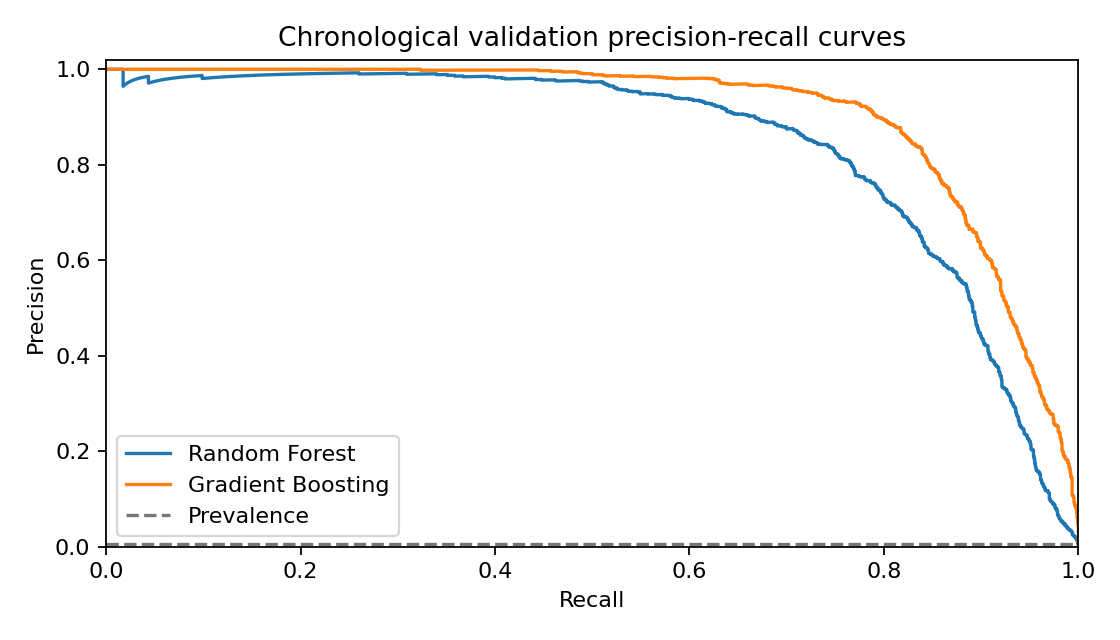

history


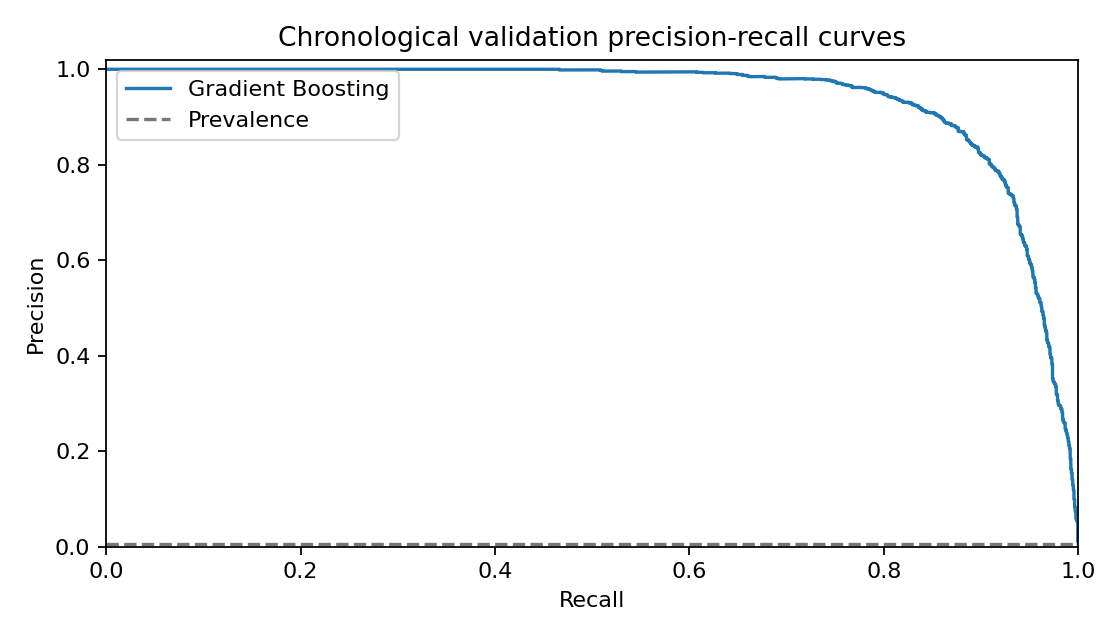

In [4]:
baseline = pd.read_csv(PROJECT / 'results/validation_comparison.csv')
baseline = baseline[baseline.model.eq('Random Forest')].assign(experiment='Original baseline')
tables = [baseline]
for name in experiments:
    table = pd.read_csv(ARTIFACTS / name / 'validation_comparison.csv')
    tables.append(table[table.model.eq('Gradient Boosting')].assign(experiment=name))
comparison = pd.concat(tables, ignore_index=True)
display(comparison[['experiment', 'precision', 'recall', 'f1', 'average_precision', 'fp', 'fn', 'threshold']])
for name in experiments:
    print(name)
    display(Image(filename=str(ARTIFACTS / name / 'validation_pr.png')))


## 4 Verify deployment uses the same history as validation

The verification replays the whole validation period using the demo's scoring
function and the earlier training period as explicit context. It compares scores
with the training pipeline's precomputed-history path and checks the saved metrics.
It reads only fraudTrain.csv, not official test labels. Expected score difference:
zero. Functional parity does not establish performance on a fresh population.

In [5]:
parity = verify(DATA_DIR, ARTIFACTS / 'history')
display(pd.Series(parity))
assert parity['validation_inference_max_absolute_difference'] == 0.0
assert not parity['official_test_evaluated']


history_version                                                        strict-timestamp-groups-v2
context_rows                                                                              1037340
review_rows                                                                                259335
model_sha256                                    7d3f19981c909b2a710681769c962b6ac698f438a72332...
training_sha256                                 fd7139200dbfcbed0b6742bbe05a4f1abce532c4fef209...
validation_inference_max_absolute_difference                                                  0.0
official_test_evaluated                                                                     False
threshold                                                                                0.901028
rows                                                                                       259335
fraud                                                                                        1538
accuracy            

## 5 Demonstrate separate context and review inputs

The paired example retains complete validation histories for a few selected cards
and their earlier training histories, using matched pseudonymous IDs. It is not a
representative performance sample. Context must end before review begins; overlapping
files are rejected. New review rows can use earlier rows within the same review
batch, but not same-time peers. Context is not automatically updated between uploads.
For a later batch, provide the appropriately expanded earlier history explicitly.

The local Customer history tab also supports an explicit No prior history option.
Unknown cards are identified rather than assumed to have established histories.
Their performance is not claimed to match the contextual validation table.

In [6]:
history_dir = ARTIFACTS / 'history'
context = validate_input(pd.read_csv(history_dir / 'demo_history.csv', dtype={'cc_num': 'string'}), history=True)
review = pd.read_csv(history_dir / 'demo_transactions.csv', dtype={'cc_num': 'string'})
saved = load_bundle(history_dir / 'selected_model.joblib')
scored = score_transactions(review, saved, context)
print('Earlier context rows:', len(context), '| Review rows:', len(review), '| Flags:', int(scored.review_flag.sum()))
display(scored.head(10))
assert {'cc_num', 'dob', 'first', 'last', 'is_fraud'}.isdisjoint(scored.columns)


Earlier context rows: 3683 | Review rows: 999 | Flags: 78


,row_number,transaction_time,category,amount_usd,model_score,review_flag,prior_transactions,customer_status
597,598,2020-05-10 22:01:43,shopping_net,1147.75,0.999984,True,4,History available
452,453,2020-04-25 23:21:53,shopping_net,978.42,0.999981,True,7,History available
266,267,2020-04-07 03:58:09,gas_transport,9.79,0.999980,True,2,History available
588,589,2020-05-09 23:01:40,shopping_net,1016.08,0.999979,True,2,History available
589,590,2020-05-09 23:31:43,shopping_net,1100.62,0.999978,True,3,History available
450,451,2020-04-25 22:51:37,shopping_net,954.23,0.999977,True,6,History available
441,442,2020-04-25 03:10:19,grocery_pos,336.51,0.999977,True,2,History available
632,633,2020-05-12 23:47:18,shopping_pos,919.80,0.999973,True,8,History available
598,599,2020-05-10 22:33:34,shopping_net,1167.35,0.999972,True,5,History available
601,602,2020-05-10 23:51:44,shopping_net,1036.79,0.999971,True,8,History available


## 6 Regression tests and preserved final-test evidence

Tests cover same-time order independence, no look-ahead, validation/inference parity,
context overlap, cold starts, browser isolation, expiry, invalid inputs and privacy.
The original Random Forest test result is displayed below solely as existing evidence.
No official test evaluation is called, and neither new model inherits that result.

In [7]:
checked = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                         cwd=PROJECT, capture_output=True, text=True)
print(checked.stdout + checked.stderr)
assert checked.returncode == 0
baseline_test = json.loads((PROJECT / 'results/final_test.json').read_text())
display(pd.Series({k: baseline_test[k] for k in ['precision', 'recall', 'f1', 'tp', 'fp', 'fn', 'tn']}))
print('Previously recorded Random Forest test only. New models: validation only.')


test_batch_mode_matches_precomputed_mode (test_history.HistoryTests.test_batch_mode_matches_precomputed_mode) ... ok
test_context_matches_full_stream (test_history.HistoryTests.test_context_matches_full_stream) ... ok
test_history_inputs_required (test_history.HistoryTests.test_history_inputs_required) ... ok
test_independent_of_row_order (test_history.HistoryTests.test_independent_of_row_order) ... ok
test_known_values (test_history.HistoryTests.test_known_values) ... ok
test_no_lookahead (test_history.HistoryTests.test_no_lookahead) ... ok
test_all_simultaneous_rows_have_no_prior_history (test_history_context.ContextTests.test_all_simultaneous_rows_have_no_prior_history) ... ok
test_expired_context_is_not_reused (test_history_context.ContextTests.test_expired_context_is_not_reused) ... ok
test_explicit_cold_start_and_unknown_card (test_history_context.ContextTests.test_explicit_cold_start_and_unknown_card) ... ok
test_future_and_overlapping_context_rejected (test_history_context.Cont

precision         0.689345
recall            0.751049
f1                0.718876
tp             1611.000000
fp              726.000000
fn              534.000000
tn           552848.000000
dtype: float64

Previously recorded Random Forest test only. New models: validation only.


## 7 Local demo and limitations

Run `python -m uvicorn app:app --host 127.0.0.1 --port 8766` from this phase folder.
Batch review retains the original model and transaction-only Gradient Boosting;
Customer history uses separate earlier-history/review inputs; Model evaluation
shows each model's own evidence. A fresh clone needs generated artifacts first;
the baseline can be recreated with train.py into artifacts/baseline without
rerunning official test evaluation.

History uploads allow 2,000,000 rows / 512 MB; review batches allow 50,000 / 20 MB.
Context is local RAM only, session scoped, clearable and expires after an hour.
Uploads never retrain models. Raw datasets and model binaries stay outside Git.

Remaining limitations: synthetic data, previously explored validation, geographic
and demographic proxies, short-history/cold-start distribution shifts, no independent
new holdout for the improved models, and no production banking integration.
Team usability testing and the instructor's final presentation/report remain required.